# VentiMorph-RelNet | Journal analysis, part 1

Summarize training histories, fold-level validation results, patient-level OOF metrics and lesion-size findings. Figures and analysis tables are exported from the saved runs.

**Inputs:** five frozen-fold training output bundles and the completed five-fold OOF results archive. Attach the inputs under `/kaggle/input` before running.

**Output:** the Step 1 figures, tables and analysis ZIP in `/kaggle/working`.


In [1]:
from __future__ import annotations

import io
import re
import json
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working/ventimorph_v281_journal_analysis_step1")
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
EXTRACT_DIR = OUTPUT_DIR / "extracted_inputs"

for p in [OUTPUT_DIR, FIG_DIR, TABLE_DIR, EXTRACT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Input root:", INPUT_ROOT)
print("No retraining will be performed.")
print("Locked-test evaluation: DISABLED")
print("GPU is not required.")


Input root: /kaggle/input
No retraining will be performed.
Locked-test evaluation: DISABLED
GPU is not required.


In [2]:
def _metadata_fold_for_directory(directory: Path):
    metadata_path = directory / "transfer_metadata.json"
    if not metadata_path.exists():
        return None
    try:
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    except Exception:
        return None

    value = metadata.get("fold", None)
    if value is not None:
        try:
            return int(value)
        except Exception:
            pass

    run_directory = str(metadata.get("run_directory", ""))
    match = re.search(r"(?:^|[_\-/])fold(\d+)(?:[_\-/]|$)", run_directory.lower())
    if match:
        return int(match.group(1))

    return None


def _parent_folder_fold(history_path: Path):
    """
    Resolve fold from the history file's immediate parent folder, e.g.
    MS3SEG_V281_FOLD3_FULL60_TRANSFER -> 3.
    This deliberately ignores higher-level Kaggle dataset names.
    """
    parent_name = history_path.parent.name
    match = re.search(
        r"MS3SEG_V281_FOLD(\d+)_FULL60_TRANSFER",
        parent_name,
        flags=re.IGNORECASE,
    )
    if match:
        return int(match.group(1))

    # Fallback for a directly exposed run directory.
    match = re.search(
        r"(?:^|[_-])fold(\d+)(?:[_-]|$)",
        parent_name.lower(),
    )
    if match:
        return int(match.group(1))

    return None


def find_fold_history(fold: int):
    """
    Supports BOTH:
    1) Kaggle-extracted transfer folders containing history.csv
    2) attached .zip transfer packages containing history.csv

    Fold identity is resolved from transfer_metadata.json when present,
    otherwise from the immediate transfer-folder name. Higher-level Kaggle
    dataset names are never used to decide the fold.
    """

    direct_candidates = []

    for history_path in INPUT_ROOT.rglob("history.csv"):
        metadata_fold = _metadata_fold_for_directory(history_path.parent)
        folder_fold = _parent_folder_fold(history_path)

        resolved_fold = (
            metadata_fold
            if metadata_fold is not None
            else folder_fold
        )

        if resolved_fold == fold:
            direct_candidates.append(history_path)

    if direct_candidates:
        # If duplicates exist, prefer exact FULL60 transfer folder names, then shortest path.
        direct_candidates = sorted(
            direct_candidates,
            key=lambda p: (
                not bool(re.search(
                    rf"MS3SEG_V281_FOLD{fold}_FULL60_TRANSFER",
                    p.parent.name,
                    flags=re.IGNORECASE,
                )),
                len(str(p)),
            ),
        )

        selected = direct_candidates[0]

        # Final hard verification.
        metadata_fold = _metadata_fold_for_directory(selected.parent)
        folder_fold = _parent_folder_fold(selected)

        if metadata_fold is not None and metadata_fold != fold:
            raise RuntimeError(
                f"Selected Fold {fold} history has transfer metadata fold={metadata_fold}: {selected}"
            )
        if folder_fold is not None and folder_fold != fold:
            raise RuntimeError(
                f"Selected Fold {fold} history folder identifies fold={folder_fold}: {selected}"
            )

        return {
            "mode": "direct",
            "history": selected,
            "source": selected.parent,
        }

    # Otherwise search attached ZIP files by the ZIP's own filename.
    zip_candidates = [
        p for p in INPUT_ROOT.rglob("*.zip")
        if re.match(
            rf"^MS3SEG_V281_FOLD{fold}_FULL60_TRANSFER(?: \(\d+\))?\.zip$",
            p.name,
            flags=re.IGNORECASE,
        )
    ]

    if zip_candidates:
        zip_path = sorted(
            zip_candidates,
            key=lambda p: p.stat().st_size,
            reverse=True,
        )[0]

        fold_extract = EXTRACT_DIR / f"fold{fold}"
        if fold_extract.exists():
            shutil.rmtree(fold_extract)
        fold_extract.mkdir(parents=True, exist_ok=True)

        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(fold_extract)

        histories = list(fold_extract.rglob("history.csv"))
        if not histories:
            raise FileNotFoundError(
                f"Fold {fold} transfer ZIP does not contain history.csv: {zip_path}"
            )

        selected = histories[0]
        metadata_fold = _metadata_fold_for_directory(selected.parent)
        if metadata_fold is not None and metadata_fold != fold:
            raise RuntimeError(
                f"Fold {fold} ZIP contains transfer metadata fold={metadata_fold}: {zip_path}"
            )

        return {
            "mode": "zip",
            "history": selected,
            "source": zip_path,
        }

    raise FileNotFoundError(
        f"Could not find the correct Fold {fold} history.csv or matching FULL60 transfer ZIP.\n"
        f"Attach the completed Fold {fold} training output dataset."
    )


fold_sources = {}
histories = {}

for fold in range(5):
    info = find_fold_history(fold)
    fold_sources[fold] = info
    histories[fold] = pd.read_csv(info["history"])

    if int(histories[fold]["epoch"].max()) != 60:
        raise RuntimeError(
            f"Fold {fold} history does not contain all 60 epochs. "
            f"Maximum recorded epoch: {histories[fold]['epoch'].max()}"
        )

    print(
        f"Fold {fold}: {info['mode']} input -> {info['history']} "
        f"(epochs={int(histories[fold]['epoch'].max())})"
    )

# Strong duplicate-source guard: every fold must resolve to a unique history path/source.
resolved_histories = [str(fold_sources[f]["history"]) for f in range(5)]
if len(set(resolved_histories)) != 5:
    raise RuntimeError(
        "Fold matching failed: two or more folds resolved to the same history.csv. "
        f"Resolved histories: {resolved_histories}"
    )

print("All five training histories loaded successfully.")
print("Fold-to-history mapping is unique and verified.")


Fold 0: direct input -> /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD0_FULL60_TRANSFER (1)/history.csv (epochs=60)
Fold 1: direct input -> /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD1_FULL60_TRANSFER/history.csv (epochs=60)
Fold 2: direct input -> /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD2_FULL60_TRANSFER/history.csv (epochs=60)
Fold 3: direct input -> /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD3_FULL60_TRANSFER/history.csv (epochs=60)
Fold 4: direct input -> /kaggle/input/datasets/sabatasnim123/ms3seg-v281-fold0-fold4-full60-transfer/MS3SEG_V281_FOLD4_FULL60_TRANSFER/history.csv (epochs=60)
All five training histories loaded successfully.
Fold-to-history mapping is unique and verified.


In [3]:
REQUIRED_OOF_FILES = [
    "v281_5fold_oof_patient_metrics.csv",
    "v281_5fold_oof_lesion_metrics.csv",
    "v281_5fold_oof_fold_summary.csv",
    "v281_5fold_oof_overall_summary.csv",
    "v281_5fold_oof_class_summary.csv",
    "v281_5fold_oof_confusion_matrix.csv",
    "v281_checkpoint_audit.csv",
    "evaluation_metadata.json",
]


def locate_oof_file(name):
    direct = list(INPUT_ROOT.rglob(name))
    if direct:
        return direct[0]

    # Also support an attached results ZIP.
    result_zips = [
        p for p in INPUT_ROOT.rglob("*.zip")
        if p.name.startswith("MS3SEG_V281_5FOLD_OOF_VALIDATION_RESULTS")
    ]

    for zpath in result_zips:
        with zipfile.ZipFile(zpath, "r") as zf:
            matches = [n for n in zf.namelist() if Path(n).name == name]
            if matches:
                target = EXTRACT_DIR / "oof" / name
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(zf.read(matches[0]))
                return target

    raise FileNotFoundError(
        f"Could not find required OOF result: {name}\n"
        "Attach the completed MS3SEG_V281_5FOLD_OOF_VALIDATION_RESULTS dataset."
    )


oof_paths = {
    name: locate_oof_file(name)
    for name in REQUIRED_OOF_FILES
}

for name, path in oof_paths.items():
    print(name, "->", path)

patient_df = pd.read_csv(oof_paths["v281_5fold_oof_patient_metrics.csv"])
lesion_df = pd.read_csv(oof_paths["v281_5fold_oof_lesion_metrics.csv"])
fold_oof_df = pd.read_csv(oof_paths["v281_5fold_oof_fold_summary.csv"])
overall_df = pd.read_csv(oof_paths["v281_5fold_oof_overall_summary.csv"])
class_df = pd.read_csv(oof_paths["v281_5fold_oof_class_summary.csv"])
confusion_df = pd.read_csv(
    oof_paths["v281_5fold_oof_confusion_matrix.csv"],
    index_col=0,
)
checkpoint_audit_df = pd.read_csv(oof_paths["v281_checkpoint_audit.csv"])

evaluation_metadata = json.loads(
    Path(oof_paths["evaluation_metadata.json"]).read_text(encoding="utf-8")
)

if len(patient_df) != 80 or patient_df["patient_id"].nunique() != 80:
    raise RuntimeError(
        f"Expected 80 unique OOF development patients; "
        f"found rows={len(patient_df)}, unique={patient_df['patient_id'].nunique()}."
    )

if bool(evaluation_metadata.get("locked_test_evaluated", False)):
    raise RuntimeError(
        "OOF metadata indicates locked-test evaluation. "
        "This Step 1 notebook must use development/OOF results only."
    )

print("OOF inputs verified.")
print("OOF patients:", patient_df["patient_id"].nunique())
print("Locked-test evaluated:", evaluation_metadata.get("locked_test_evaluated"))


v281_5fold_oof_patient_metrics.csv -> /kaggle/input/datasets/sabatasnim123/ventimorph-5fold-oof-validation-results/v281_5fold_oof_patient_metrics.csv
v281_5fold_oof_lesion_metrics.csv -> /kaggle/input/datasets/sabatasnim123/ventimorph-5fold-oof-validation-results/v281_5fold_oof_lesion_metrics.csv
v281_5fold_oof_fold_summary.csv -> /kaggle/input/datasets/sabatasnim123/ventimorph-5fold-oof-validation-results/v281_5fold_oof_fold_summary.csv
v281_5fold_oof_overall_summary.csv -> /kaggle/input/datasets/sabatasnim123/ventimorph-5fold-oof-validation-results/v281_5fold_oof_overall_summary.csv
v281_5fold_oof_class_summary.csv -> /kaggle/input/datasets/sabatasnim123/ventimorph-5fold-oof-validation-results/v281_5fold_oof_class_summary.csv
v281_5fold_oof_confusion_matrix.csv -> /kaggle/input/datasets/sabatasnim123/ventimorph-5fold-oof-validation-results/v281_5fold_oof_confusion_matrix.csv
v281_checkpoint_audit.csv -> /kaggle/input/datasets/sabatasnim123/ventimorph-5fold-oof-validation-results/v281

In [4]:
# Save an audit table recording exactly which Kaggle inputs were analyzed.
input_audit = pd.DataFrame([
    {
        "type": "training_history",
        "fold": fold,
        "source": str(info["source"]),
        "resolved_file": str(info["history"]),
        "epochs": int(histories[fold]["epoch"].max()),
    }
    for fold, info in fold_sources.items()
])

input_audit.to_csv(
    TABLE_DIR / "input_audit_training_histories.csv",
    index=False,
)

oof_input_audit = pd.DataFrame([
    {
        "required_file": name,
        "resolved_path": str(path),
    }
    for name, path in oof_paths.items()
])

oof_input_audit.to_csv(
    TABLE_DIR / "input_audit_oof_results.csv",
    index=False,
)

display(input_audit)
display(oof_input_audit)


,type,fold,source,resolved_file,epochs
0,training_history,0,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,60
1,training_history,1,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,60
2,training_history,2,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,60
3,training_history,3,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,60
4,training_history,4,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,/kaggle/input/datasets/sabatasnim123/ms3seg-v2...,60


,required_file,resolved_path
0,v281_5fold_oof_patient_metrics.csv,/kaggle/input/datasets/sabatasnim123/ventimorp...
1,v281_5fold_oof_lesion_metrics.csv,/kaggle/input/datasets/sabatasnim123/ventimorp...
2,v281_5fold_oof_fold_summary.csv,/kaggle/input/datasets/sabatasnim123/ventimorp...
3,v281_5fold_oof_overall_summary.csv,/kaggle/input/datasets/sabatasnim123/ventimorp...
4,v281_5fold_oof_class_summary.csv,/kaggle/input/datasets/sabatasnim123/ventimorp...
5,v281_5fold_oof_confusion_matrix.csv,/kaggle/input/datasets/sabatasnim123/ventimorp...
6,v281_checkpoint_audit.csv,/kaggle/input/datasets/sabatasnim123/ventimorp...
7,evaluation_metadata.json,/kaggle/input/datasets/sabatasnim123/ventimorp...


In [5]:
# Build training summary table.
training_rows = []

for fold, history in histories.items():
    best_balanced = history.loc[
        history["val_balanced_score"].idxmax()
    ]
    best_fg = history.loc[
        history["val_mean_fg_dice"].idxmax()
    ]

    training_rows.append({
        "fold": fold,
        "best_balanced_epoch": int(best_balanced["epoch"]),
        "best_balanced_score": float(best_balanced["val_balanced_score"]),
        "mean_fg_at_best_balanced": float(best_balanced["val_mean_fg_dice"]),
        "best_fg_epoch": int(best_fg["epoch"]),
        "best_mean_fg_dice": float(best_fg["val_mean_fg_dice"]),
        "ventricle_dice_at_best_balanced": float(best_balanced["val_dice_vent"]),
        "normal_wmh_dice_at_best_balanced": float(best_balanced["val_dice_nwmh"]),
        "abnormal_wmh_dice_at_best_balanced": float(best_balanced["val_dice_abwmh"]),
        "max_mean_gradient_norm": float(history["mean_gradient_norm"].max()),
        "total_skipped_batches": int(history["skipped_batches"].sum()),
        "rollbacks_used": int(history["rollbacks_used"].max()),
    })

training_summary = pd.DataFrame(training_rows)
training_summary.to_csv(
    TABLE_DIR / "v281_5fold_training_summary.csv",
    index=False,
)

display(training_summary)


,fold,best_balanced_epoch,best_balanced_score,mean_fg_at_best_balanced,best_fg_epoch,best_mean_fg_dice,ventricle_dice_at_best_balanced,normal_wmh_dice_at_best_balanced,abnormal_wmh_dice_at_best_balanced,max_mean_gradient_norm,total_skipped_batches,rollbacks_used
0,0,49,0.803969,0.824617,49,0.824617,0.911893,0.713757,0.848201,12.672361,9,0
1,1,43,0.801378,0.821933,43,0.821933,0.921188,0.719852,0.824759,12.099643,10,0
2,2,42,0.793707,0.813574,45,0.813936,0.917666,0.724837,0.798218,12.058386,10,0
3,3,50,0.804630,0.823637,50,0.823637,0.914066,0.728056,0.828788,11.347911,9,0
4,4,28,0.795242,0.815171,28,0.815171,0.911860,0.716628,0.817024,12.393720,8,0


In [6]:
def save_figure(name):
    plt.tight_layout()
    plt.savefig(
        FIG_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.savefig(
        FIG_DIR / f"{name}.pdf",
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


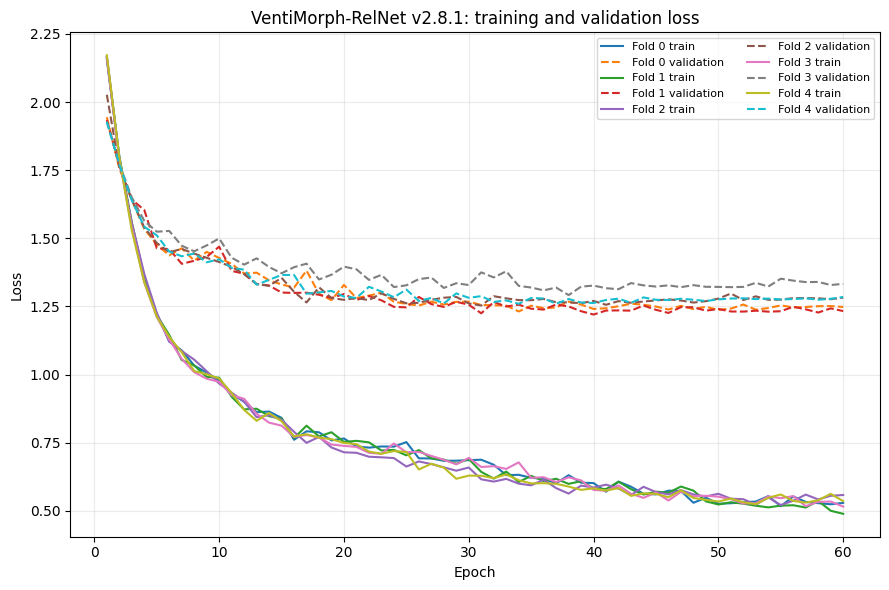

In [7]:
# Figure 1: training and validation loss curves.
plt.figure(figsize=(9, 6))
for fold, history in histories.items():
    plt.plot(
        history["epoch"],
        history["train_loss"],
        label=f"Fold {fold} train",
    )
    plt.plot(
        history["epoch"],
        history["val_loss"],
        linestyle="--",
        label=f"Fold {fold} validation",
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VentiMorph-RelNet v2.8.1: training and validation loss")
plt.legend(ncol=2, fontsize=8)
plt.grid(alpha=0.25)
save_figure("Figure01_training_validation_loss_5fold")


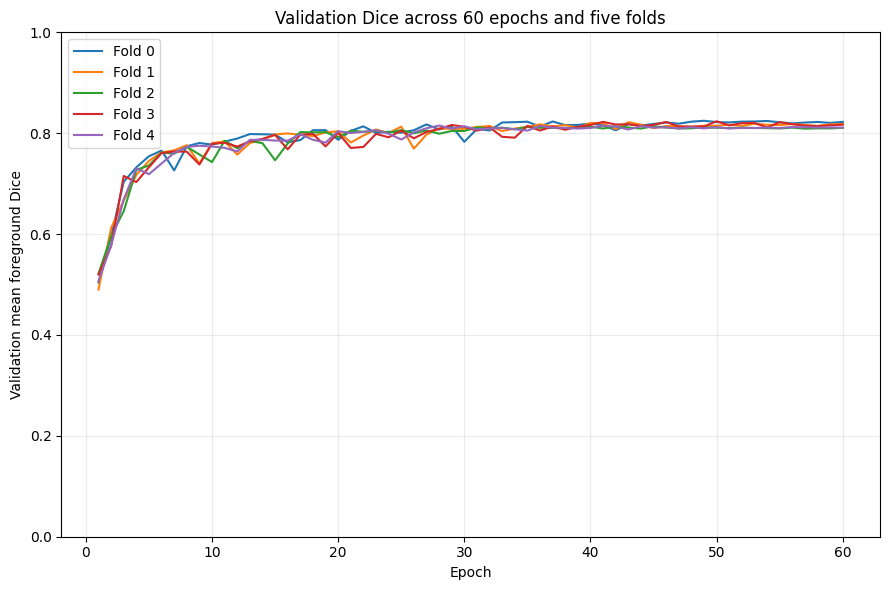

In [8]:
# Figure 2: validation mean foreground Dice for all five folds.
plt.figure(figsize=(9, 6))
for fold, history in histories.items():
    plt.plot(
        history["epoch"],
        history["val_mean_fg_dice"],
        label=f"Fold {fold}",
    )

plt.xlabel("Epoch")
plt.ylabel("Validation mean foreground Dice")
plt.title("Validation Dice across 60 epochs and five folds")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.25)
save_figure("Figure02_validation_mean_fg_dice_5fold")


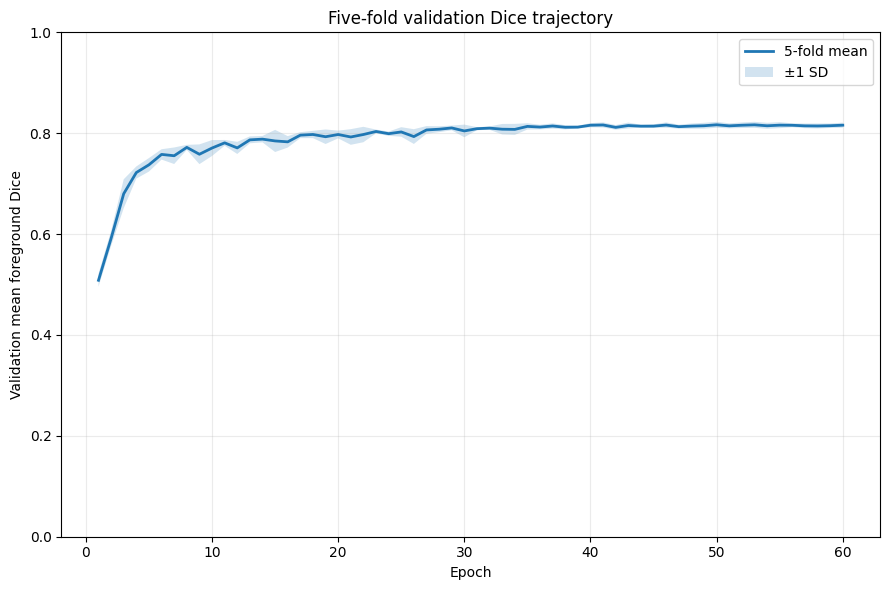

In [9]:
# Figure 3: five-fold mean ± SD validation Dice.
epochs = histories[0]["epoch"].to_numpy()
matrix = np.vstack([
    histories[f]["val_mean_fg_dice"].to_numpy()
    for f in range(5)
])

mean_curve = matrix.mean(axis=0)
std_curve = matrix.std(axis=0, ddof=1)

plt.figure(figsize=(9, 6))
plt.plot(
    epochs,
    mean_curve,
    linewidth=2,
    label="5-fold mean",
)
plt.fill_between(
    epochs,
    mean_curve - std_curve,
    mean_curve + std_curve,
    alpha=0.2,
    label="±1 SD",
)

plt.xlabel("Epoch")
plt.ylabel("Validation mean foreground Dice")
plt.title("Five-fold validation Dice trajectory")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.25)
save_figure("Figure03_validation_dice_mean_sd")


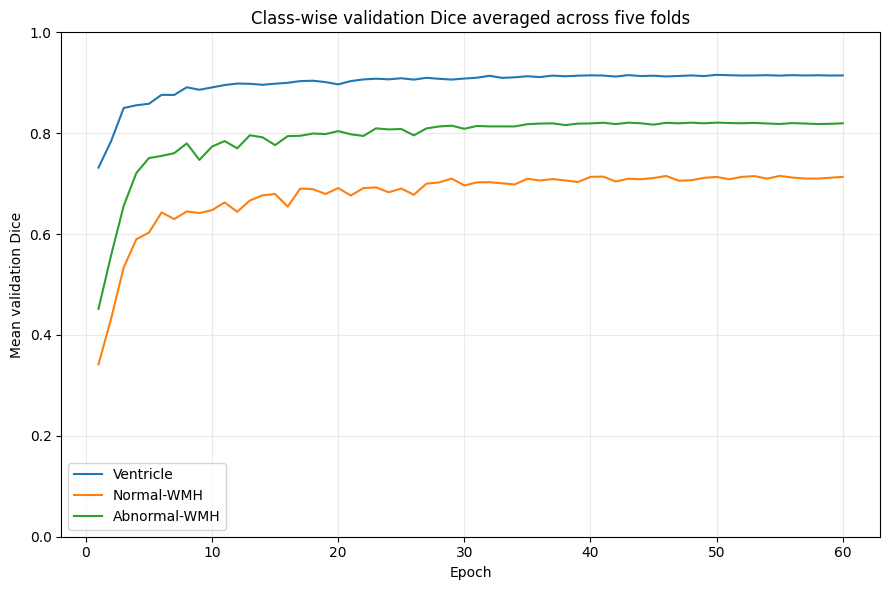

In [10]:
# Figure 4: class-wise mean validation Dice.
class_columns = {
    "Ventricle": "val_dice_vent",
    "Normal-WMH": "val_dice_nwmh",
    "Abnormal-WMH": "val_dice_abwmh",
}

plt.figure(figsize=(9, 6))

for label, column in class_columns.items():
    matrix = np.vstack([
        histories[f][column].to_numpy()
        for f in range(5)
    ])
    plt.plot(
        epochs,
        matrix.mean(axis=0),
        label=label,
    )

plt.xlabel("Epoch")
plt.ylabel("Mean validation Dice")
plt.title("Class-wise validation Dice averaged across five folds")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.25)
save_figure("Figure04_classwise_validation_dice")


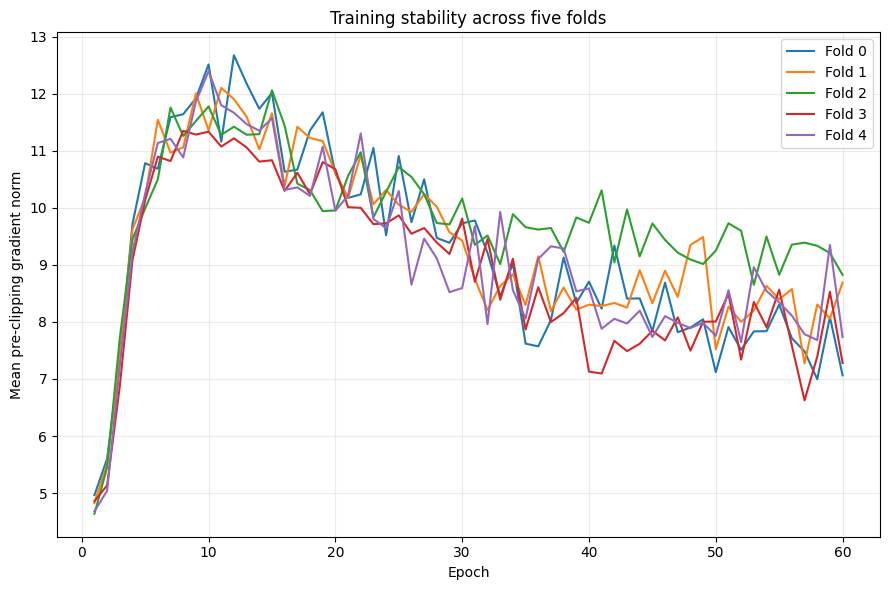

In [11]:
# Figure 5: gradient/stability curves.
plt.figure(figsize=(9, 6))

for fold, history in histories.items():
    plt.plot(
        history["epoch"],
        history["mean_gradient_norm"],
        label=f"Fold {fold}",
    )

plt.xlabel("Epoch")
plt.ylabel("Mean pre-clipping gradient norm")
plt.title("Training stability across five folds")
plt.legend()
plt.grid(alpha=0.25)
save_figure("Figure05_gradient_norm_5fold")


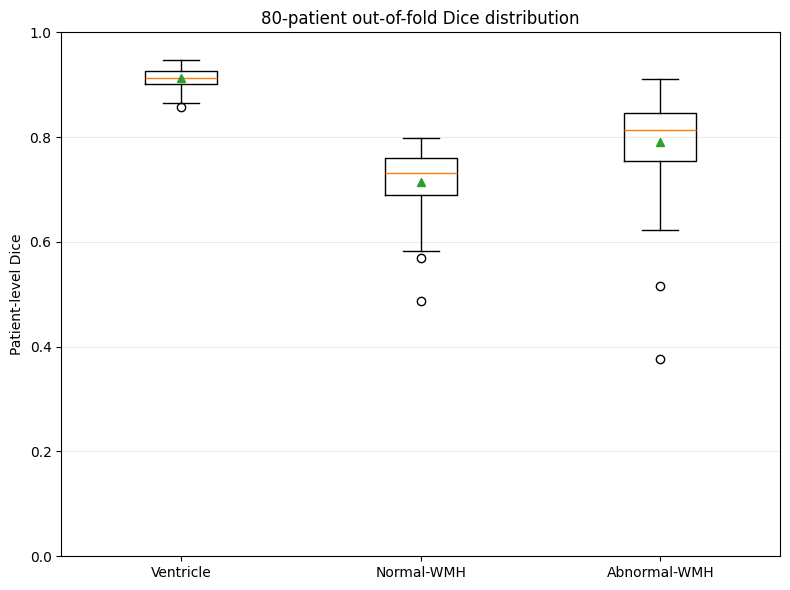

In [12]:
# Figure 6: patient-level OOF Dice distributions.
dice_columns = [
    "ventricle_dice",
    "normal_wmh_dice",
    "abnormal_wmh_dice",
]
labels = [
    "Ventricle",
    "Normal-WMH",
    "Abnormal-WMH",
]

plt.figure(figsize=(8, 6))
plt.boxplot(
    [
        patient_df[c].dropna().to_numpy()
        for c in dice_columns
    ],
    tick_labels=labels,
    showmeans=True,
)

plt.ylabel("Patient-level Dice")
plt.title("80-patient out-of-fold Dice distribution")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.25)
save_figure("Figure06_oof_dice_boxplot")


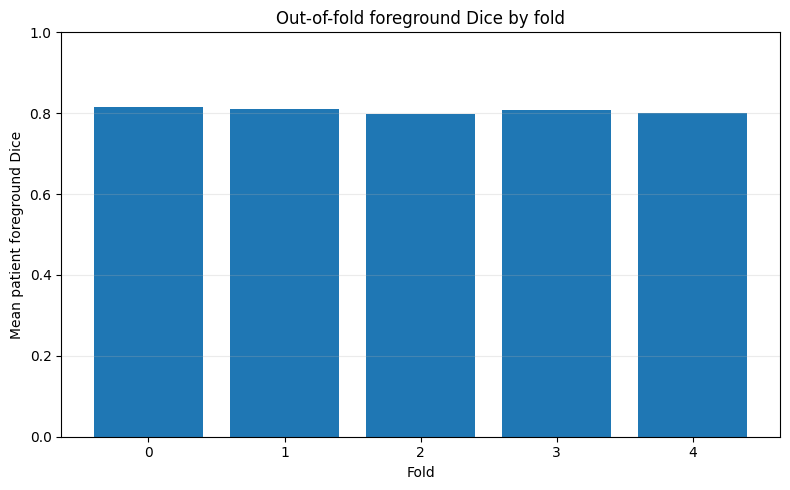

In [13]:
# Figure 7: OOF performance by fold.
plt.figure(figsize=(8, 5))
plt.bar(
    fold_oof_df["fold"].astype(str),
    fold_oof_df["mean_fg_dice"],
)

plt.xlabel("Fold")
plt.ylabel("Mean patient foreground Dice")
plt.title("Out-of-fold foreground Dice by fold")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.25)
save_figure("Figure07_oof_mean_fg_by_fold")


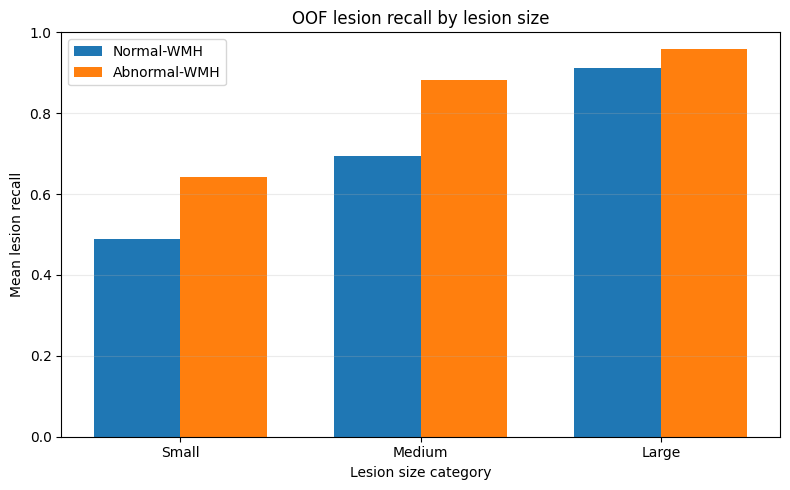

In [14]:
# Figure 8: lesion recall by lesion size.
size_columns = [
    ("Small", "small_lesion_recall"),
    ("Medium", "medium_lesion_recall"),
    ("Large", "large_lesion_recall"),
]

size_rows = []

for lesion_class in [
    "normal_wmh",
    "abnormal_wmh",
]:
    class_rows = lesion_df[
        lesion_df["class"] == lesion_class
    ]

    for size_label, column in size_columns:
        values = pd.to_numeric(
            class_rows[column],
            errors="coerce",
        )

        size_rows.append({
            "class": lesion_class,
            "size": size_label,
            "mean_recall": values.mean(),
            "std_recall": values.std(ddof=1),
            "valid_patients": int(values.notna().sum()),
        })

lesion_size_summary = pd.DataFrame(size_rows)
lesion_size_summary.to_csv(
    TABLE_DIR / "v281_lesion_size_recall_summary.csv",
    index=False,
)

x = np.arange(3)
width = 0.36

normal_values = [
    lesion_size_summary[
        (lesion_size_summary["class"] == "normal_wmh")
        & (lesion_size_summary["size"] == size)
    ]["mean_recall"].iloc[0]
    for size, _ in size_columns
]

abnormal_values = [
    lesion_size_summary[
        (lesion_size_summary["class"] == "abnormal_wmh")
        & (lesion_size_summary["size"] == size)
    ]["mean_recall"].iloc[0]
    for size, _ in size_columns
]

plt.figure(figsize=(8, 5))
plt.bar(
    x - width / 2,
    normal_values,
    width,
    label="Normal-WMH",
)
plt.bar(
    x + width / 2,
    abnormal_values,
    width,
    label="Abnormal-WMH",
)

plt.xticks(x, [s for s, _ in size_columns])
plt.xlabel("Lesion size category")
plt.ylabel("Mean lesion recall")
plt.title("OOF lesion recall by lesion size")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.25)
save_figure("Figure08_lesion_size_recall")


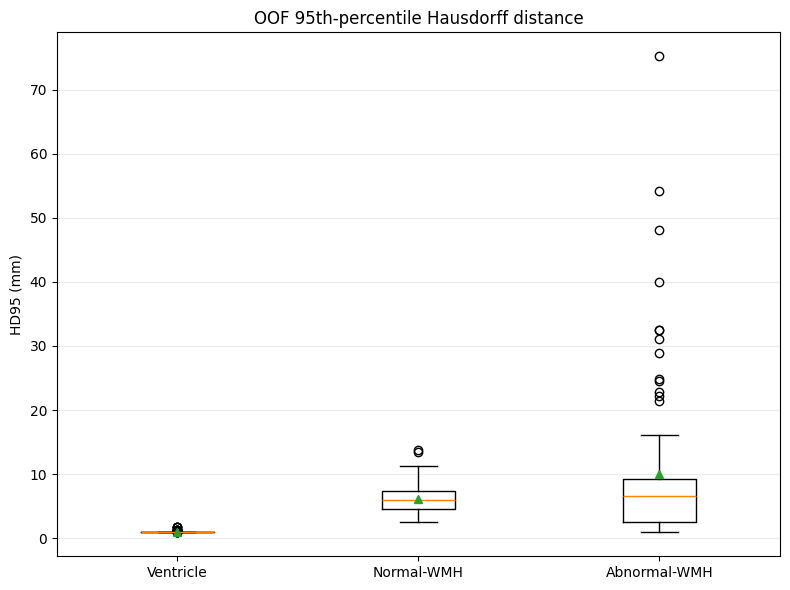

In [15]:
# Figure 9: HD95 distributions.
hd95_columns = [
    "ventricle_hd95_mm",
    "normal_wmh_hd95_mm",
    "abnormal_wmh_hd95_mm",
]

plt.figure(figsize=(8, 6))
plt.boxplot(
    [
        pd.to_numeric(
            patient_df[c],
            errors="coerce",
        )
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .to_numpy()
        for c in hd95_columns
    ],
    tick_labels=[
        "Ventricle",
        "Normal-WMH",
        "Abnormal-WMH",
    ],
    showmeans=True,
)

plt.ylabel("HD95 (mm)")
plt.title("OOF 95th-percentile Hausdorff distance")
plt.grid(axis="y", alpha=0.25)
save_figure("Figure09_oof_hd95_boxplot")


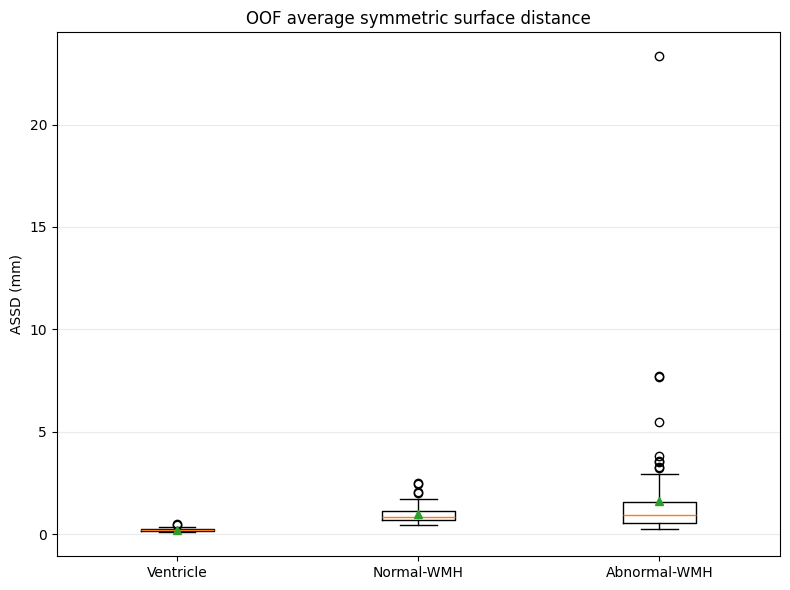

In [16]:
# Figure 10: ASSD distributions.
assd_columns = [
    "ventricle_assd_mm",
    "normal_wmh_assd_mm",
    "abnormal_wmh_assd_mm",
]

plt.figure(figsize=(8, 6))
plt.boxplot(
    [
        pd.to_numeric(
            patient_df[c],
            errors="coerce",
        )
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .to_numpy()
        for c in assd_columns
    ],
    tick_labels=[
        "Ventricle",
        "Normal-WMH",
        "Abnormal-WMH",
    ],
    showmeans=True,
)

plt.ylabel("ASSD (mm)")
plt.title("OOF average symmetric surface distance")
plt.grid(axis="y", alpha=0.25)
save_figure("Figure10_oof_assd_boxplot")


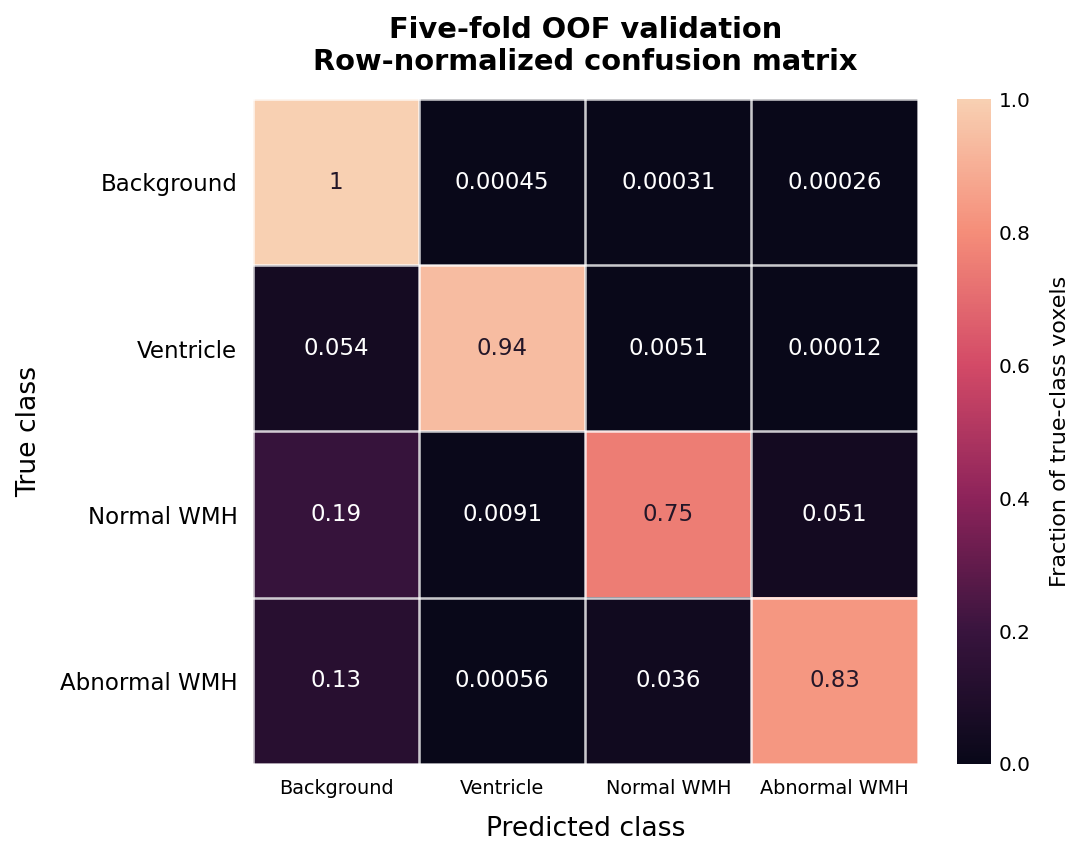

In [17]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

CLASS_NAMES = ["Background", "Ventricle", "Normal WMH", "Abnormal WMH"]

# Match the original dark-purple / peach confusion matrices.
REFERENCE_CMAP = LinearSegmentedColormap.from_list(
    "purple_peach", ["#090819", "#39143e", "#8d235a", "#d34a67", "#f58d79", "#f8d0b2"], N=256
)


def _normalize_confusion(counts):
    counts = np.asarray(counts, dtype=np.float64)
    if counts.shape != (4, 4) or np.any(counts < 0) or not np.isfinite(counts).all():
        raise ValueError("Expected a 4x4 matrix of nonnegative voxel counts")
    totals = counts.sum(axis=1, keepdims=True)
    if np.any(totals == 0):
        raise ValueError("Each class must contain reference voxels")
    return counts / totals


def _draw_matrix(ax, normalized, title, show_ylabel=True, font_size=11):
    image = ax.imshow(normalized, cmap=REFERENCE_CMAP, vmin=0, vmax=1,
                      interpolation="nearest", aspect="equal")
    ax.set_title(title, fontsize=13, fontweight="semibold", pad=13)
    ax.set_xticks(np.arange(4), CLASS_NAMES, fontsize=max(font_size - 1.6, 8.5))
    ax.set_yticks(np.arange(4), CLASS_NAMES, fontsize=font_size)
    ax.set_xlabel("Predicted class", fontsize=12, labelpad=8)
    if show_ylabel:
        ax.set_ylabel("True class", fontsize=12, labelpad=8)
    ax.tick_params(axis="both", length=0, pad=7)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 4, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.15, alpha=0.78)
    ax.tick_params(which="minor", bottom=False, left=False)

    for row in range(4):
        for col in range(4):
            value = float(normalized[row, col])
            label = f"{value:.2g}" if value > 0 else "0"
            ax.text(col, row, label, ha="center", va="center",
                    color="#231628" if value >= 0.58 else "#ffffff",
                    fontsize=font_size, fontweight="medium")
    return image


def confusion_figure(counts, title, output_dir, stem, display=True):
    normalized = _normalize_confusion(counts)
    fig, ax = plt.subplots(figsize=(8.15, 6.20), dpi=160)
    fig.patch.set_facecolor("white")
    image = _draw_matrix(ax, normalized, title, font_size=10.3)
    bar = fig.colorbar(image, ax=ax, fraction=0.045, pad=0.043)
    bar.set_label("Fraction of true-class voxels", fontsize=10, labelpad=9)
    bar.ax.tick_params(labelsize=9, length=0)
    bar.outline.set_visible(False)
    fig.subplots_adjust(left=0.19, right=0.90, bottom=0.16, top=0.83)

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    for suffix in ("png", "pdf", "svg"):
        fig.savefig(output_dir / f"{stem}.{suffix}",
                    dpi=350 if suffix == "png" else None,
                    bbox_inches="tight", facecolor="white")
    if display:
        plt.show()
    plt.close(fig)
    return normalized


def read_confusion_csv(data):
    import pandas as pd
    from io import BytesIO
    table = pd.read_csv(BytesIO(data) if isinstance(data, bytes) else data)
    columns = ["pred_background", "pred_ventricle",
               "pred_normal_wmh", "pred_abnormal_wmh"]
    missing = [column for column in columns if column not in table.columns]
    if missing:
        raise ValueError(f"Missing confusion-matrix columns: {missing}")
    return table[columns].to_numpy(dtype=np.int64)


def compare_confusion_figures(oof_counts, locked_counts, output_dir,
                              stem="OOF_vs_LockedTest", display=True):
    matrices = [_normalize_confusion(oof_counts), _normalize_confusion(locked_counts)]
    titles = ["Five-fold OOF validation", "20-patient locked test"]
    fig, axes = plt.subplots(1, 2, figsize=(14.3, 5.65), dpi=160)
    for ax, normalized, title in zip(axes, matrices, titles):
        image = _draw_matrix(ax, normalized, title, font_size=9.0)
    bar = fig.colorbar(image, ax=axes.tolist(), fraction=0.024, pad=0.025, shrink=0.83)
    bar.set_label("Fraction of true-class voxels", fontsize=10)
    bar.ax.tick_params(length=0, labelsize=9)
    bar.outline.set_visible(False)
    fig.subplots_adjust(left=0.095, right=0.88, bottom=0.18, top=0.86, wspace=0.26)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    for suffix in ("png", "pdf", "svg"):
        fig.savefig(output_dir / f"{stem}.{suffix}",
                    dpi=350 if suffix == "png" else None,
                    bbox_inches="tight", facecolor="white")
    if display:
        plt.show()
    plt.close(fig)
    return matrices


normalized = confusion_figure(
    confusion_df.to_numpy(dtype=np.int64),
    "Five-fold OOF validation\nRow-normalized confusion matrix",
    FIG_DIR,
    "Figure11_oof_normalized_confusion_matrix",
)


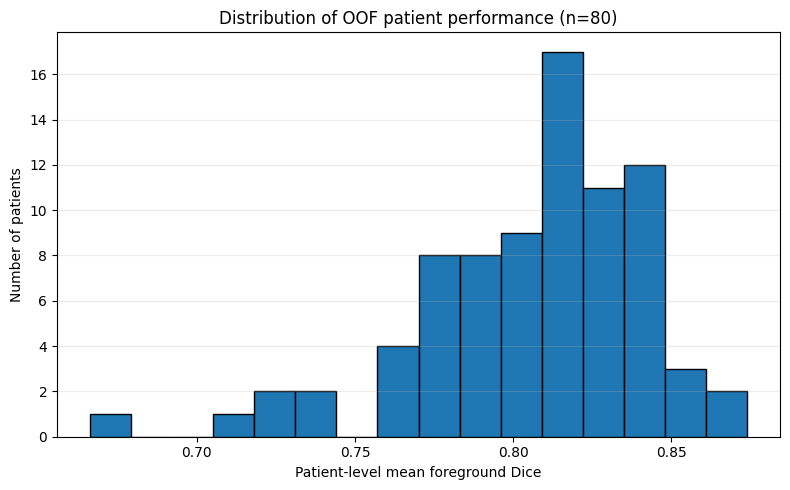

In [18]:
# Figure 12: patient-level mean foreground Dice distribution.
plt.figure(figsize=(8, 5))
plt.hist(
    patient_df["mean_foreground_dice"]
    .dropna()
    .to_numpy(),
    bins=16,
    edgecolor="black",
)

plt.xlabel("Patient-level mean foreground Dice")
plt.ylabel("Number of patients")
plt.title("Distribution of OOF patient performance (n=80)")
plt.grid(axis="y", alpha=0.25)
save_figure("Figure12_oof_patient_fg_dice_histogram")


In [19]:
# Identify best/worst patients for later qualitative/XAI analysis.
case_columns = [
    "patient_id",
    "fold",
    "mean_foreground_dice",
    "ventricle_dice",
    "normal_wmh_dice",
    "abnormal_wmh_dice",
    "normal_wmh_lesion_f1",
    "abnormal_wmh_lesion_f1",
    "periventricular_abnormal_fp_rate",
]

ranked_cases = patient_df[
    case_columns
].sort_values(
    "mean_foreground_dice"
)

worst_cases = ranked_cases.head(10)
best_cases = ranked_cases.tail(10).sort_values(
    "mean_foreground_dice",
    ascending=False,
)

worst_cases.to_csv(
    TABLE_DIR / "v281_10_worst_oof_cases.csv",
    index=False,
)
best_cases.to_csv(
    TABLE_DIR / "v281_10_best_oof_cases.csv",
    index=False,
)

print("10 weakest OOF cases:")
display(worst_cases)

print("10 strongest OOF cases:")
display(best_cases)


10 weakest OOF cases:


,patient_id,fold,mean_foreground_dice,ventricle_dice,normal_wmh_dice,abnormal_wmh_dice,normal_wmh_lesion_f1,abnormal_wmh_lesion_f1,periventricular_abnormal_fp_rate
63,98,3,0.666229,0.947589,0.674286,0.376812,0.636364,0.333333,0.473684
74,56,4,0.715036,0.929363,0.592215,0.623529,0.500000,0.400000,0.608696
33,11,2,0.723854,0.917059,0.738780,0.515723,0.640000,0.400000,0.277778
39,50,2,0.724631,0.864358,0.643967,0.665567,0.492754,0.637681,0.377320
11,72,0,0.734464,0.903265,0.591702,0.708423,0.463768,0.833333,0.215190
27,59,1,0.740236,0.881757,0.590868,0.748081,0.500000,0.753623,0.223901
18,19,1,0.759198,0.927103,0.486797,0.863693,0.631579,0.864865,0.198488
73,52,4,0.760098,0.896642,0.696981,0.686670,0.539683,0.679245,0.050000
12,86,0,0.765873,0.856854,0.722319,0.718447,0.608696,0.571429,0.225000
46,93,2,0.767407,0.919583,0.569738,0.812899,0.242424,0.727273,0.118193


10 strongest OOF cases:


,patient_id,fold,mean_foreground_dice,ventricle_dice,normal_wmh_dice,abnormal_wmh_dice,normal_wmh_lesion_f1,abnormal_wmh_lesion_f1,periventricular_abnormal_fp_rate
54,47,3,0.873902,0.938109,0.798865,0.884731,0.580645,0.912281,0.204790
61,84,3,0.867340,0.918563,0.776067,0.907390,0.592593,0.869565,0.172727
21,28,1,0.859439,0.937622,0.767904,0.872793,0.633333,0.756757,0.127432
14,95,0,0.858893,0.894869,0.769969,0.911839,0.769231,0.740741,0.121272
20,26,1,0.849985,0.935205,0.765449,0.849302,0.666667,0.844444,0.176817
45,82,2,0.847282,0.916819,0.747534,0.877493,0.469136,0.787879,0.153382
9,64,0,0.843811,0.906977,0.764940,0.859517,0.675676,0.820513,0.179567
71,37,4,0.842848,0.923748,0.736748,0.868047,0.567568,0.738462,0.142551
32,4,2,0.842748,0.923092,0.788524,0.816630,0.779661,0.761905,0.284274
28,61,1,0.840602,0.920134,0.741176,0.860495,0.623377,0.833333,0.156342


In [20]:
# Manuscript-ready OOF metrics table.
metrics_to_report = [
    ("Mean foreground Dice", "mean_foreground_dice"),
    ("Ventricle Dice", "ventricle_dice"),
    ("Normal-WMH Dice", "normal_wmh_dice"),
    ("Abnormal-WMH Dice", "abnormal_wmh_dice"),
    ("Normal-WMH lesion F1", "normal_wmh_lesion_f1"),
    ("Abnormal-WMH lesion F1", "abnormal_wmh_lesion_f1"),
    ("Normal-WMH small-lesion recall", "normal_wmh_small_lesion_recall"),
    ("Abnormal-WMH small-lesion recall", "abnormal_wmh_small_lesion_recall"),
    ("Periventricular abnormal-WMH FP rate", "periventricular_abnormal_fp_rate"),
]

report_rows = []

for label, column in metrics_to_report:
    values = pd.to_numeric(
        patient_df[column],
        errors="coerce",
    )

    report_rows.append({
        "Metric": label,
        "Mean": values.mean(),
        "SD": values.std(ddof=1),
        "Median": values.median(),
        "Minimum": values.min(),
        "Maximum": values.max(),
        "N": int(values.notna().sum()),
        "Mean ± SD": (
            f"{values.mean():.4f} ± "
            f"{values.std(ddof=1):.4f}"
        ),
    })

manuscript_table = pd.DataFrame(report_rows)
manuscript_table.to_csv(
    TABLE_DIR / "v281_manuscript_oof_metrics_table.csv",
    index=False,
)

display(manuscript_table)


,Metric,Mean,SD,Median,Minimum,Maximum,N,Mean ± SD
0,Mean foreground Dice,0.806272,0.036189,0.814827,0.666229,0.873902,80,0.8063 ± 0.0362
1,Ventricle Dice,0.912787,0.017724,0.913251,0.856854,0.947589,80,0.9128 ± 0.0177
2,Normal-WMH Dice,0.714956,0.060540,0.732229,0.486797,0.798865,80,0.7150 ± 0.0605
3,Abnormal-WMH Dice,0.791074,0.083359,0.812644,0.376812,0.911839,80,0.7911 ± 0.0834
4,Normal-WMH lesion F1,0.574617,0.096715,0.586016,0.242424,0.791667,80,0.5746 ± 0.0967
5,Abnormal-WMH lesion F1,0.751757,0.106026,0.767594,0.333333,0.912281,80,0.7518 ± 0.1060
6,Normal-WMH small-lesion recall,0.488447,0.122453,0.490000,0.142857,0.772727,80,0.4884 ± 0.1225
7,Abnormal-WMH small-lesion recall,0.642987,0.190652,0.666667,0.157895,1.000000,78,0.6430 ± 0.1907
8,Periventricular abnormal-WMH FP rate,0.230310,0.138505,0.202124,0.007576,1.000000,80,0.2303 ± 0.1385


In [21]:
analysis_metadata = {
    "model": "VentiMorph-RelNet-v2.8.1-segmentation-first",
    "stage": "journal_analysis_step1_input_driven",
    "retraining_performed": False,
    "locked_test_evaluated": False,
    "training_folds": [0, 1, 2, 3, 4],
    "training_epochs_per_fold": 60,
    "oof_patients": 80,
    "input_driven": True,
    "next_stage": (
        "probability-level PR/ROC/calibration, "
        "qualitative segmentation/error panels, and VentiMorph-specific XAI"
    ),
}

(OUTPUT_DIR / "analysis_metadata.json").write_text(
    json.dumps(
        analysis_metadata,
        indent=2,
    ),
    encoding="utf-8",
)

archive_path = shutil.make_archive(
    "/kaggle/working/MS3SEG_V281_JOURNAL_ANALYSIS_STEP1_INPUT_DRIVEN_v2_FIXED",
    "zip",
    root_dir=OUTPUT_DIR,
)

print("STEP 1 complete.")
print("Download:")
print(
    "/kaggle/working/"
    "MS3SEG_V281_JOURNAL_ANALYSIS_STEP1_INPUT_DRIVEN_v2_FIXED.zip"
)
print("No retraining performed.")
print("Locked-test evaluated: False")


STEP 1 complete.
Download:
/kaggle/working/MS3SEG_V281_JOURNAL_ANALYSIS_STEP1_INPUT_DRIVEN_v2_FIXED.zip
No retraining performed.
Locked-test evaluated: False
